# Phase 7: Ligand–Receptor Communication & TME Received Signal Analysis

### Overview
In this analysis, we characterize cell–cell communication between the tumour microenvironment (TME) lineages (T-cells, B-cells, Myeloid, NK cells, Plasma cells, Fibroblasts, Endothelial) and **Thyrocytes** across thyroid cancer progression stages.

We calculate:
1. Canonical ligand–receptor interaction scores (Mean Ligand in Sender x Mean Receptor in Target) across all cell lineages.
2. Pathway-level aggregation for key oncogenic & microenvironmental cascades (TGF-beta, Chemokine, Integrin/ECM, ErbB/EGFR, Immune/Stromal checkpoint, etc.).
3. Thyrocyte-specific **'Received Signal'** scores per cell, mapping microenvironmental pressure onto thyrocyte differentiation states.


In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import anndata

PROCESSED_DIR = os.path.join(os.getcwd(), "processed_data")

comm_df = pd.read_csv(os.path.join(PROCESSED_DIR, "ligand_receptor_communication_atlas.csv"))
thy_signals = pd.read_csv(os.path.join(PROCESSED_DIR, "thyrocyte_received_signals_by_pathway.csv"))
print(f"Loaded {len(comm_df)} ligand-receptor interactions across atlas lineages.")
comm_df.head(10)


Loaded 1024 ligand-receptor interactions across atlas lineages.


sender,target,ligand,receptor,pair,pathway,ligand_mean,receptor_mean,ligand_pct,receptor_pct,communication_score
B cells,B cells,CXCL12,CXCR4,CXCL12-CXCR4,Chemokine,0.000492,2.753959,0.000304,0.935258,1.354761e-03
B cells,B cells,CCL2,CCR2,CCL2-CCR2,Chemokine,0.010979,0.004578,0.006296,0.003126,5.026407e-05
B cells,B cells,TGFB1,TGFBR1,TGFB1-TGFBR1,TGF-beta,0.246171,0.028307,0.157273,0.019409,6.968343e-03
B cells,B cells,TGFB1,TGFBR2,TGFB1-TGFBR2,TGF-beta,0.246171,0.231368,0.157273,0.148719,5.695606e-02
B cells,B cells,TGFA,EGFR,TGFA-EGFR,ErbB/EGFR,0.000956,0.000572,0.000608,0.000347,5.462475e-07
B cells,B cells,FGF2,FGFR1,FGF2-FGFR1,FGF,0.000144,0.009987,0.000087,0.007772,1.438306e-06
B cells,B cells,VEGFA,KDR,VEGFA-KDR,VEGF,0.004388,0.000177,0.002822,0.000087,7.787579e-07
B cells,B cells,VEGFA,FLT1,VEGFA-FLT1,VEGF,0.004388,0.009680,0.002822,0.006470,4.248040e-05
B cells,B cells,IL6,IL6R,IL6-IL6R,Interleukin,0.110223,0.015567,0.063482,0.012505,1.715796e-03
B cells,B cells,TNF,TNFRSF1A,TNF-TNFRSF1A,TNF,0.067388,0.009493,0.043248,0.006991,6.397078e-04


### Cell 2: TME-to-Thyrocyte Communication Landscape
We filter for signals targeted specifically to **Thyrocytes** to assess which microenvironmental cells exert the strongest signaling pressure on malignant and premalignant thyroid follicular cells.


In [2]:
top_thy_signals = comm_df[comm_df["target"] == "Thyrocytes"].sort_values("communication_score", ascending=False)
print("Top 15 TME -> Thyrocyte Ligand-Receptor Interactions:")
display_cols = ["sender", "ligand", "receptor", "pathway", "communication_score"]
print(top_thy_signals[display_cols].head(15).to_string(index=False))


Top 15 TME -> Thyrocyte Ligand-Receptor Interactions:
      sender ligand receptor        pathway  communication_score
  Thyrocytes    FN1    ITGB1   Integrin/ECM             2.424487
 Endothelial    APP     CD74 Immune/Stromal             1.922808
 Fibroblasts    FN1    ITGB1   Integrin/ECM             1.904749
  Thyrocytes    MIF     CD74 Immune/Stromal             1.594086
 Fibroblasts    MIF     CD74 Immune/Stromal             1.503197
 Endothelial    FN1    ITGB1   Integrin/ECM             1.333969
     Myeloid    FN1    ITGB1   Integrin/ECM             1.098067
Plasma cells    FN1    ITGB1   Integrin/ECM             1.096323
Plasma cells    MIF     CD74 Immune/Stromal             1.014617
  Thyrocytes    FN1    ITGAV   Integrin/ECM             1.010051
 Endothelial    MIF     CD74 Immune/Stromal             0.953185
  Thyrocytes    APP     CD74 Immune/Stromal             0.930718
    NK cells    MIF     CD74 Immune/Stromal             0.877117
     Myeloid    MIF     CD74 Immune/

### Cell 3: Pathway Received Signal Heatmap
We summarize the incoming signal intensity across signaling pathways and sender cell types.


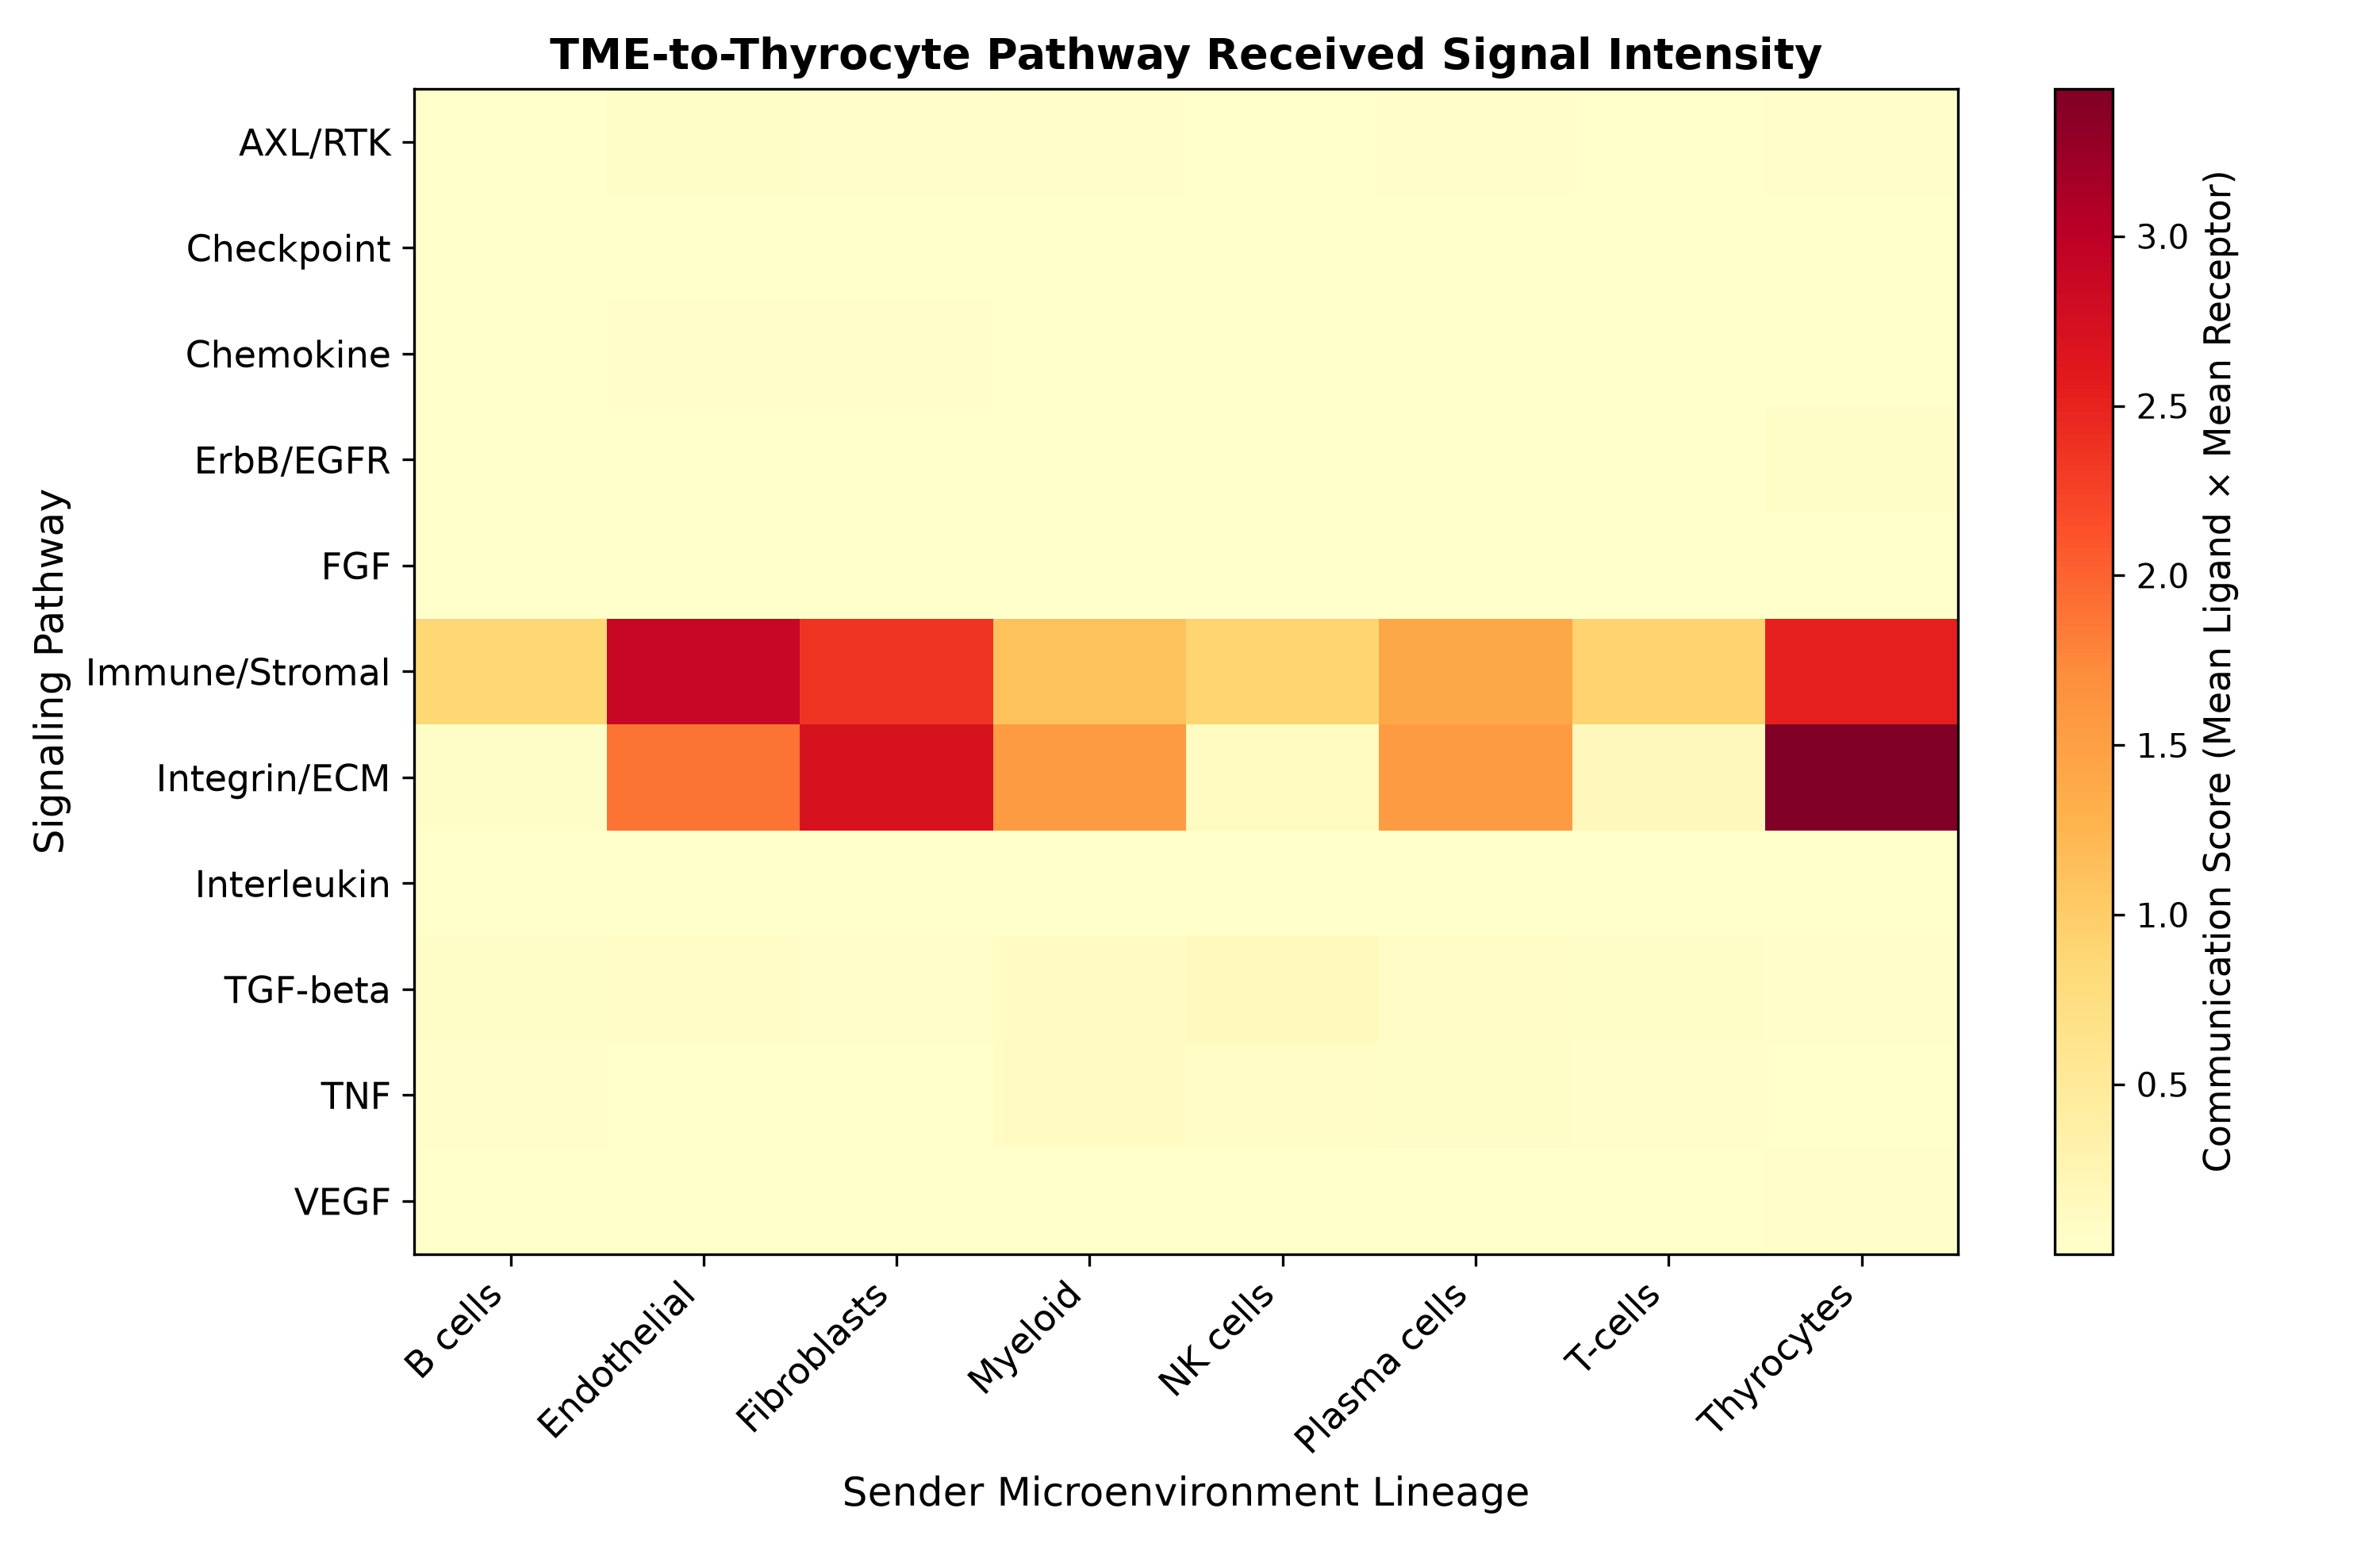

In [3]:
pivot = thy_signals.pivot(index="pathway", columns="sender", values="communication_score").fillna(0)

plt.figure(figsize=(10, 6.5))
plt.imshow(pivot.values, cmap="YlOrRd", aspect="auto")
plt.xticks(np.arange(len(pivot.columns)), pivot.columns, rotation=45, ha="right", fontsize=11)
plt.yticks(np.arange(len(pivot.index)), pivot.index, fontsize=11)
plt.title("TME-to-Thyrocyte Pathway Received Signal Intensity", fontsize=13, fontweight="bold")
plt.xlabel("Sender Microenvironment Lineage", fontsize=12)
plt.ylabel("Signaling Pathway", fontsize=12)
cbar = plt.colorbar()
cbar.set_label("Communication Score (Mean Ligand x Mean Receptor)", fontsize=11)
plt.tight_layout()
plt.show()


### Cell 4: Single-Cell Received Signal Scores in Thyrocytes
Load per-cell received signal scores and inspect their correlation with differentiation state.


In [4]:
per_cell_signals = pd.read_csv(os.path.join(PROCESSED_DIR, "thyrocyte_per_cell_received_signals.csv"), index_col=0)
print(f"Per-cell received signal scores computed for {len(per_cell_signals)} thyrocytes across {per_cell_signals.shape[1]} pathways.")
print(per_cell_signals.describe().round(4))


Per-cell received signal scores computed for 49419 thyrocytes across 11 pathways.
       received_signal_AXL/RTK  received_signal_Checkpoint  received_signal_Chemokine  received_signal_ErbB/EGFR  received_signal_FGF  received_signal_Immune/Stromal  received_signal_Integrin/ECM  received_signal_Interleukin  received_signal_TGF-beta  received_signal_TNF  received_signal_VEGF
count               49419.0000                  49419.0000                 49419.0000                 49419.0000           49419.0000                      49419.0000                    49419.0000                   49419.0000                49419.0000           49419.0000            49419.0000
mean                    0.0078                      0.0001                     0.0028                     0.0024               0.0001                          1.1138                        0.5819                       0.0004                    0.0618               0.0439                0.0015
std                     0.0293      